# 2. Avaliação dos modelos de busca

Como avaliar um buscador sem ter um conjunto de julgamentos de relevância pronto?

**Busca por item conhecido** (*known-item search*): sorteamos músicas, recortamos um
pedaço da letra e simulamos como alguém buscaria por ela. A música de origem é a
resposta certa. Para cada música sorteada geramos 4 consultas:

| tipo | simula |
|---|---|
| trecho exato | a pessoa lembra 6 a 8 palavras seguidas |
| trecho com erros | o mesmo trecho digitado com erros e sem acento |
| palavras soltas | lembra só 5 palavras "de conteúdo", fora de ordem |
| artista + trecho | sabe o artista e 4 palavras da letra |

Métricas: **MRR**, **Sucesso@1**, **Sucesso@10** e **nDCG@10**.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # para importar o pacote `buscador`

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (9, 4)

In [2]:
from buscador import MotorDeBusca
from buscador.avaliacao import CONFIGURACOES_PADRAO, avaliar_configuracoes, gerar_consultas_item_conhecido, resumir

motor = MotorDeBusca.carregar()
print(f"{motor.n_docs:,} músicas | busca semântica: {motor.tem_semantico}")

20,000 músicas | busca semântica: True


In [3]:
consultas = gerar_consultas_item_conhecido(motor, n_por_idioma=100, semente=42)
print(len(consultas), "consultas")
consultas.groupby("tipo", sort=False).head(2)[["tipo", "idioma", "consulta", "doc_alvo"]]

800 consultas


,tipo,idioma,consulta,doc_alvo
0,trecho exato,pt,correr Ná ná ná ná ná ná ná,1862
1,trecho com erros,pt,coerer Ná ná ná ná ná ná ná,1862
2,palavras soltas,pt,naá ná agora ver ná,1862
3,artista + trecho,pt,Sorriso Maroto ná ná ná ná,1862
4,trecho exato,pt,do vosso ventre Ó clemente ó,412
5,trecho com erros,pt,do vowso ventre Ó clemente ó,412
6,palavras soltas,pt,ventre clemente sempre Rogai piedosa,412
7,artista + trecho,pt,Carlos Santorelli sempre Virgem Maria Rogai,412


In [4]:
%%time
por_consulta = avaliar_configuracoes(motor, consultas, CONFIGURACOES_PADRAO, progresso=None)

/home/tur1sm0/anaconda3/envs/recinfo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9996.72it/s]

CPU times: user 1h 23min 38s, sys: 5.47 s, total: 1h 23min 43s
Wall time: 6min 10s


## 2.1 Resultado geral

In [5]:
geral = resumir(por_consulta)
geral.style.format("{:.3f}").background_gradient(cmap="Greens", axis=0)

,MRR,sucesso@1,sucesso@10,ndcg@10
configuracao,,,,
Booleano (AND),0.610,0.561,0.698,0.624
Booleano + correção,0.728,0.664,0.845,0.749
TF-IDF,0.613,0.519,0.816,0.658
BM25,0.847,0.804,0.934,0.864
BM25 + correção,0.884,0.844,0.962,0.898
Semântico,0.137,0.102,0.216,0.153
Híbrido RRF + correção,0.477,0.336,0.859,0.562
Híbrido CombSUM + correção,0.871,0.820,0.961,0.888


## 2.2 Por tipo de consulta

tipo,trecho exato,trecho com erros,palavras soltas,artista + trecho
configuracao,,,,
Booleano (AND),0.723,0.000,0.813,0.901
Booleano + correção,0.715,0.502,0.803,0.891
TF-IDF,0.682,0.387,0.754,0.630
BM25,0.877,0.655,0.922,0.936
BM25 + correção,0.877,0.804,0.922,0.932
Semântico,0.243,0.084,0.163,0.058
Híbrido RRF + correção,0.536,0.476,0.489,0.406
Híbrido CombSUM + correção,0.872,0.802,0.905,0.904


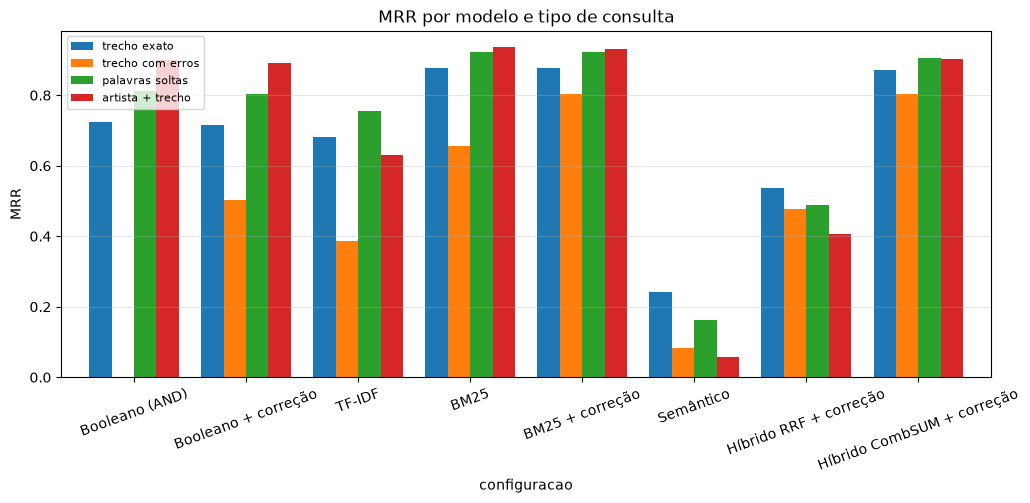

In [6]:
mrr_por_tipo = resumir(por_consulta, ["configuracao", "tipo"])["MRR"].unstack()
mrr_por_tipo = mrr_por_tipo.reindex(geral.index)[consultas["tipo"].unique()]
ax = mrr_por_tipo.plot.bar(figsize=(12, 4.5), rot=20, width=.8)
ax.set_ylabel("MRR"); ax.set_title("MRR por modelo e tipo de consulta"); ax.legend(loc="upper left", fontsize=8)
ax.grid(axis="y", alpha=.3)
mrr_por_tipo.style.format("{:.3f}").background_gradient(cmap="Greens", axis=0)

## 2.3 Por idioma

In [7]:
resumir(por_consulta, ["configuracao", "idioma"])["MRR"].unstack().reindex(geral.index).style.format("{:.3f}")

idioma,pt,en
configuracao,,
Booleano (AND),0.657,0.562
Booleano + correção,0.798,0.658
TF-IDF,0.670,0.557
BM25,0.908,0.787
BM25 + correção,0.939,0.829
Semântico,0.110,0.165
Híbrido RRF + correção,0.494,0.460
Híbrido CombSUM + correção,0.935,0.806


## 2.4 Onde cada modelo erra

Consultas em que o BM25 acertou de primeira e o semântico não, e vice-versa.

In [8]:
pivo = por_consulta.pivot_table(index=["tipo", "consulta"], columns="configuracao", values="rr")
colunas = ["BM25", "Semântico", "Híbrido CombSUM + correção"]
if "Semântico" in pivo.columns:
    print("BM25 acerta de primeira, semântico não:")
    display(pivo[(pivo["BM25"] == 1) & (pivo["Semântico"] < 1)][colunas].head(5))
    print("Semântico acerta de primeira, BM25 não:")
    display(pivo[(pivo["Semântico"] == 1) & (pivo["BM25"] < 1)][colunas].head(5))

BM25 acerta de primeira, semântico não:


configuracao                                                 BM25  Semântico  \
tipo             consulta                                                      
artista + trecho 5 Seconds Of Summer like dynamite Lips are   1.0        0.0   
                 ABBA worth the while Pushing                 1.0        0.0   
                 AVICII and Down we go                        1.0        0.0   
                 Air Supply it don't count for                1.0        0.0   
                 Air Supply rise These are the                1.0        0.0   

configuracao                                                 Híbrido CombSUM + correção  
tipo             consulta                                                                
artista + trecho 5 Seconds Of Summer like dynamite Lips are                         1.0  
                 ABBA worth the while Pushing                                       1.0  
                 AVICII and Down we go                                              1.0  
                 Air Supply it don't count for                                      1.0  
                 Air Supply rise These are the                                      1.0

Semântico acerta de primeira, BM25 não:


configuracao                                             BM25  Semântico  \
tipo             consulta                                                  
palavras soltas  What baby work Work work            0.166667        1.0   
                 ya the can how how                  0.166667        1.0   
trecho com erros de mim feccha teus ohos E sonha no  0.333333        1.0   
                 hiw can I how can I                 0.000000        1.0   
trecho exato     how can I how can I                 0.000000        1.0   

configuracao                                         Híbrido CombSUM + correção  
tipo             consulta                                                        
palavras soltas  What baby work Work work                                   0.5  
                 ya the can how how                                         0.5  
trecho com erros de mim feccha teus ohos E sonha no                         1.0  
                 hiw can I how can I                                        0.0  
trecho exato     how can I how can I                                        0.0

## 2.5 Busca por tema (o que a avaliação automática não mede)

A avaliação por item conhecido mede bem a busca por trecho, mas não a busca por
**tema**, que é onde o modelo semântico brilha. Para isso precisamos de
julgamentos humanos: é o que o app coleta com os botões 👍/👎 (veja a seção 2.6).
Alguns exemplos, inclusive entre idiomas:

In [9]:
def top(consulta, modo, k=5):
    ranking, _ = motor.ranquear(consulta, modo, k=k)
    return [f"{motor.textos['titulo'][d]} — {motor.textos['artista'][d]} ({motor.idiomas[d]})" for d, _ in ranking]

if motor.tem_semantico:
    for consulta in ["música triste sobre saudade de casa", "song about missing home", "festa na praia no verão"]:
        display(pd.DataFrame({"BM25": top(consulta, "bm25"), "Semântico": top(consulta, "semantico"),
                              "Híbrido": top(consulta, "hibrido")}, index=range(1, 6)).style.set_caption(consulta))

,BM25,Semântico,Híbrido
1,Saudade — Arlindo Cruz (pt),A Casa ao Lado — Bruno e Marrone (pt),A Casa ao Lado — Bruno e Marrone (pt)
2,A Casa ao Lado — Bruno e Marrone (pt),"No Woman, No Cry — Fugees (en)",Saudade — Arlindo Cruz (pt)
3,Dor de Verdade — Marcelo D2 (pt),A Banda - Turma Do Carrossel — Carrossel (Novela) (pt),Dor de Verdade — Marcelo D2 (pt)
4,Saudade palavra triste — Carlos Santorelli (pt),Cabelo de Trança — Tonico e Tinoco (pt),Saudade palavra triste — Carlos Santorelli (pt)
5,Da Vida — Gonzaguinha (pt),Drowse — Freddie Mercury (en),Da Vida — Gonzaguinha (pt)


,BM25,Semântico,Híbrido
1,If I Can't Have You — Shawn Mendes (en),Take You Home — Dido (en),If I Can't Have You — Shawn Mendes (en)
2,Missing — Evanescence (en),A Casa ao Lado — Bruno e Marrone (pt),Take You Home — Dido (en)
3,Before The Beginning — Fleetwood Mac (en),Coming Home (Feat. Skylar Grey) — Puff Daddy (en),Missing — Evanescence (en)
4,Missing You — Tina Turner (en),Going Home — Leonard Cohen (en),Before The Beginning — Fleetwood Mac (en)
5,Missing You — Black Eyed Peas (en),Better With You — Jason Mraz (en),Missing You — Black Eyed Peas (en)


,BM25,Semântico,Híbrido
1,Você É Desejo E Eu Sou Paixão — Leandro e Leonardo (pt),Byob — Alok (en),Barquinho de Velas — Cleber e Cauan (pt)
2,Barquinho de Velas — Cleber e Cauan (pt),Byob (Feat. Sevenn) — Alok (en),Você É Desejo E Eu Sou Paixão — Leandro e Leonardo (pt)
3,Baianidade Nagô — Anavitória (pt),A Pequena Sereia - Aqui No Mar — Disney (pt),Baianidade Nagô — Anavitória (pt)
4,Vai e Vem das Estações — Palavra Cantada (pt),Pé na Areia — Thiaguinho (pt),Vai e Vem das Estações — Palavra Cantada (pt)
5,O Barquinho — Elis Regina (pt),Club Tropicana — George Michael (en),O Barquinho — Elis Regina (pt)


## 2.6 Avaliação com os votos dos usuários

Cada 👍/👎 dado no app é salvo em `data/feedback.csv`. Esses votos formam um
conjunto de julgamentos de relevância (*qrels*) para consultas reais, e permitem
calcular P@5, P@10, nDCG@10 e MAP. Músicas não avaliadas contam como não relevantes.

In [10]:
from buscador import config
from buscador.avaliacao import avaliar_feedback

if config.ARQUIVO_FEEDBACK.exists():
    display(avaliar_feedback(motor, config.ARQUIVO_FEEDBACK))
else:
    print("Ainda não há feedback. Use o app (streamlit run app.py) e vote nos resultados.")

Ainda não há feedback. Use o app (streamlit run app.py) e vote nos resultados.


## 2.7 O que a avaliação nos ensinou

A avaliação não serviu só para medir. Ela mostrou dois erros de projeto que os
testes com exemplos não tinham revelado:

1. **Como combinar letra, título e artista.** A primeira versão tinha um índice por
   campo e somava as notas BM25 de cada um, com pesos. Nessa versão o BM25 tinha
   MRR de apenas **0,39** em trechos exatos, abaixo do booleano (0,72). O motivo é
   que cada campo tinha o seu próprio IDF: palavras comuns nas letras ("love",
   "you") são raras nos títulos, então ganhavam IDF alto ali, e qualquer música com
   "Love" no título passava na frente da música que tinha o trecho inteiro na letra.
   Juntando os campos num único documento (título e artista repetidos 2x), com um
   IDF só, o MRR em trechos exatos foi para **0,88**.

2. **Como fundir BM25 e semântico.** Com RRF, o híbrido ficou muito abaixo do BM25
   (MRR 0,48 contra 0,88). O RRF só olha posições: quando o BM25 tem certeza (nota
   da música certa muito acima das outras), o semântico, que é fraco para trechos,
   consegue derrubá-la. A soma ponderada das notas normalizadas (CombSUM, 70% BM25)
   preserva essa margem e chega a 0,87. O peso foi escolhido num conjunto de
   **desenvolvimento** gerado com outra semente, não no conjunto de teste acima.

**Limitações:** as consultas são simuladas a partir das próprias letras, o que
favorece os modelos léxicos. A busca por tema, ponto forte do semântico, só pode ser
medida com julgamentos humanos (seção 2.6).